<a href="https://colab.research.google.com/github/ManarAlmusalam-uni/image-processing-Lab8/blob/main/Lab8_Morphological.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

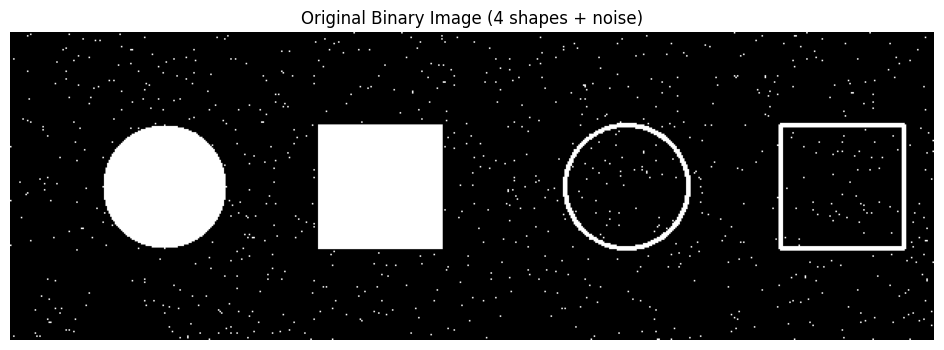

In [2]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [3]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



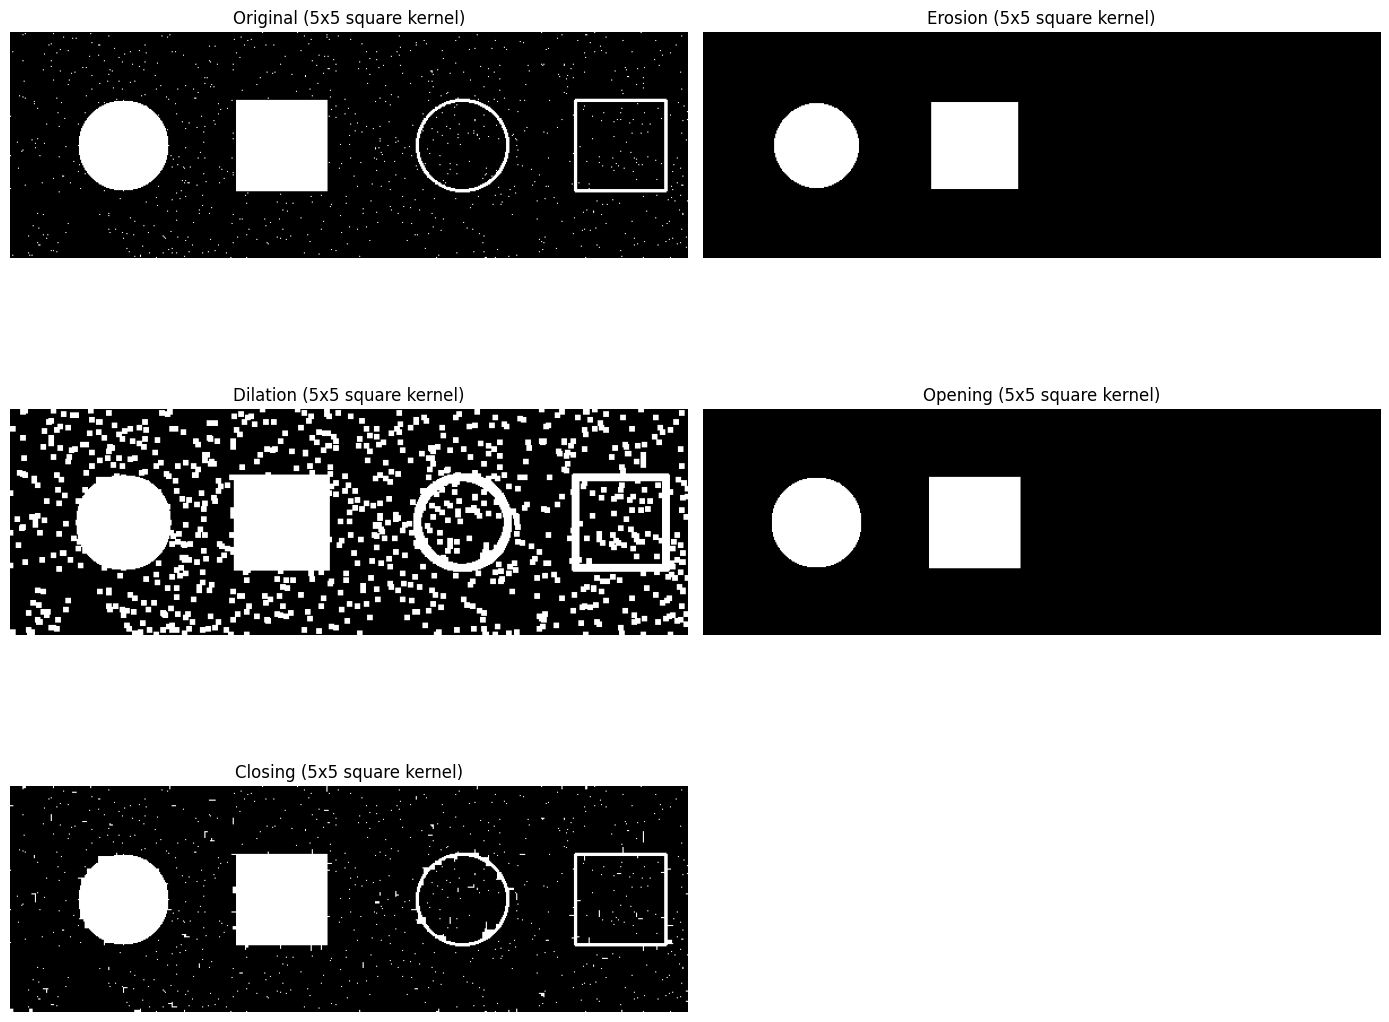

In [4]:
def show_results(image, kernel, kernel_name):
    """Apply the four morphological operations and plot them with the original."""
    erosion  = cv2.erode(image, kernel, iterations=1)
    dilation = cv2.dilate(image, kernel, iterations=1)
    opening  = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
    closing  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

    results = [("Original", image), ("Erosion", erosion), ("Dilation", dilation),
               ("Opening", opening), ("Closing", closing)]

    plt.figure(figsize=(14, 12))
    for i, (title, img) in enumerate(results, 1):
        plt.subplot(3, 2, i)
        plt.imshow(img, cmap='gray')
        plt.title(f"{title} ({kernel_name})")
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    return dict(erosion=erosion, dilation=dilation, opening=opening, closing=closing)

# Task 1: 5x5 square kernel
square_results = show_results(image, kernel, "5x5 square kernel")


## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

Circular kernel (radius 5):
[[0 0 0 0 0 1 0 0 0 0 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]]


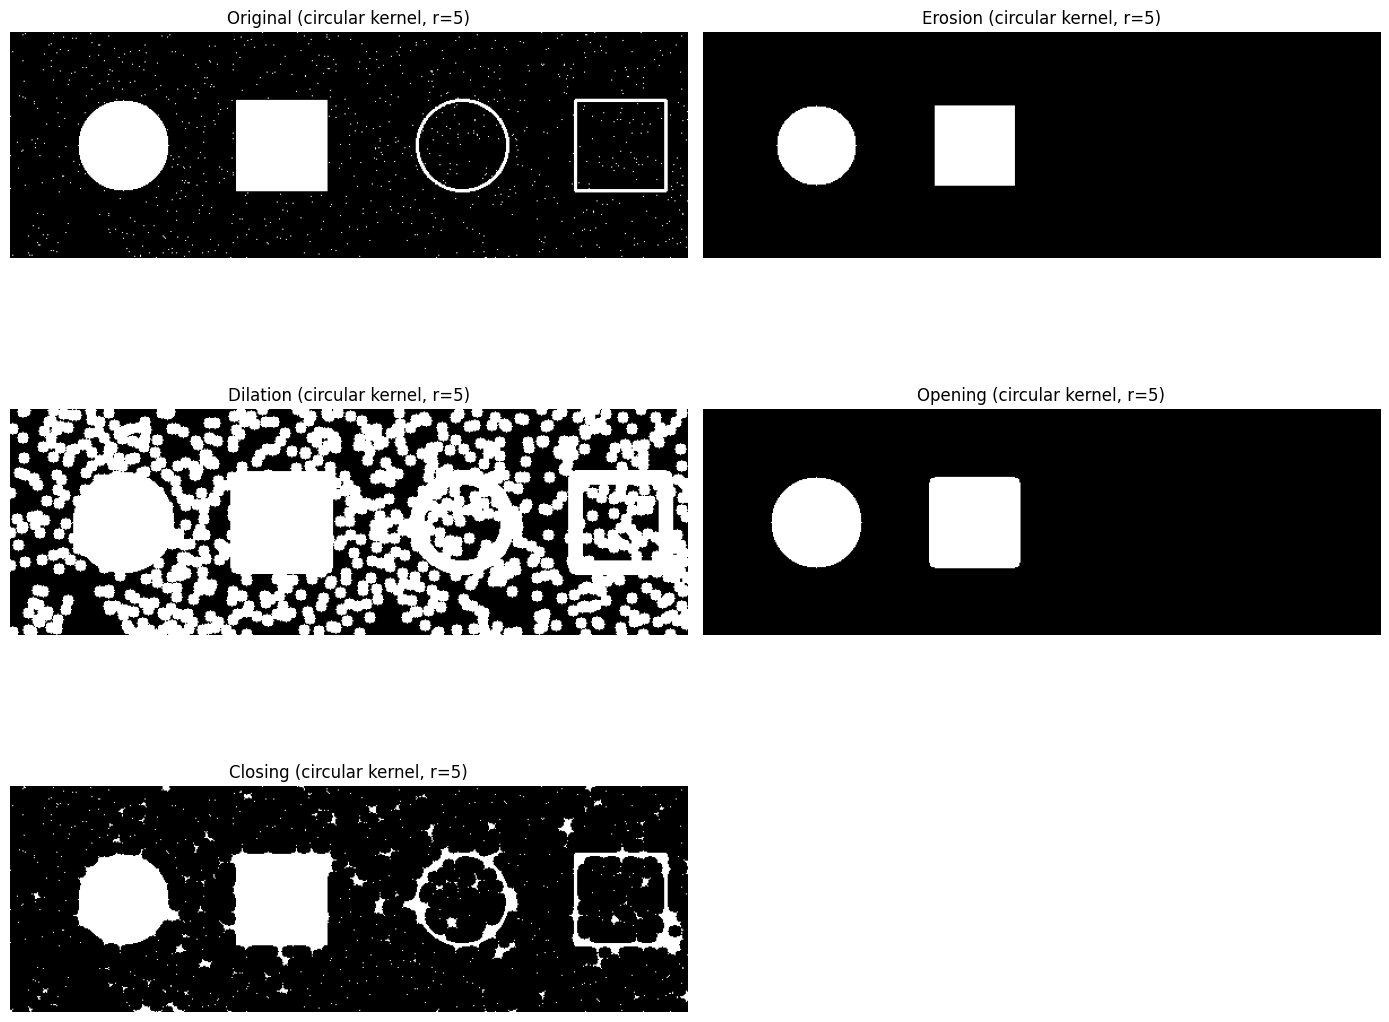

In [5]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)

# Task 2: apply all four operations with the circular kernel (radius 5 -> 11x11)
print("Circular kernel (radius 5):")
print(circle_kernel)
circle_results = show_results(image, circle_kernel, "circular kernel, r=5")


## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2


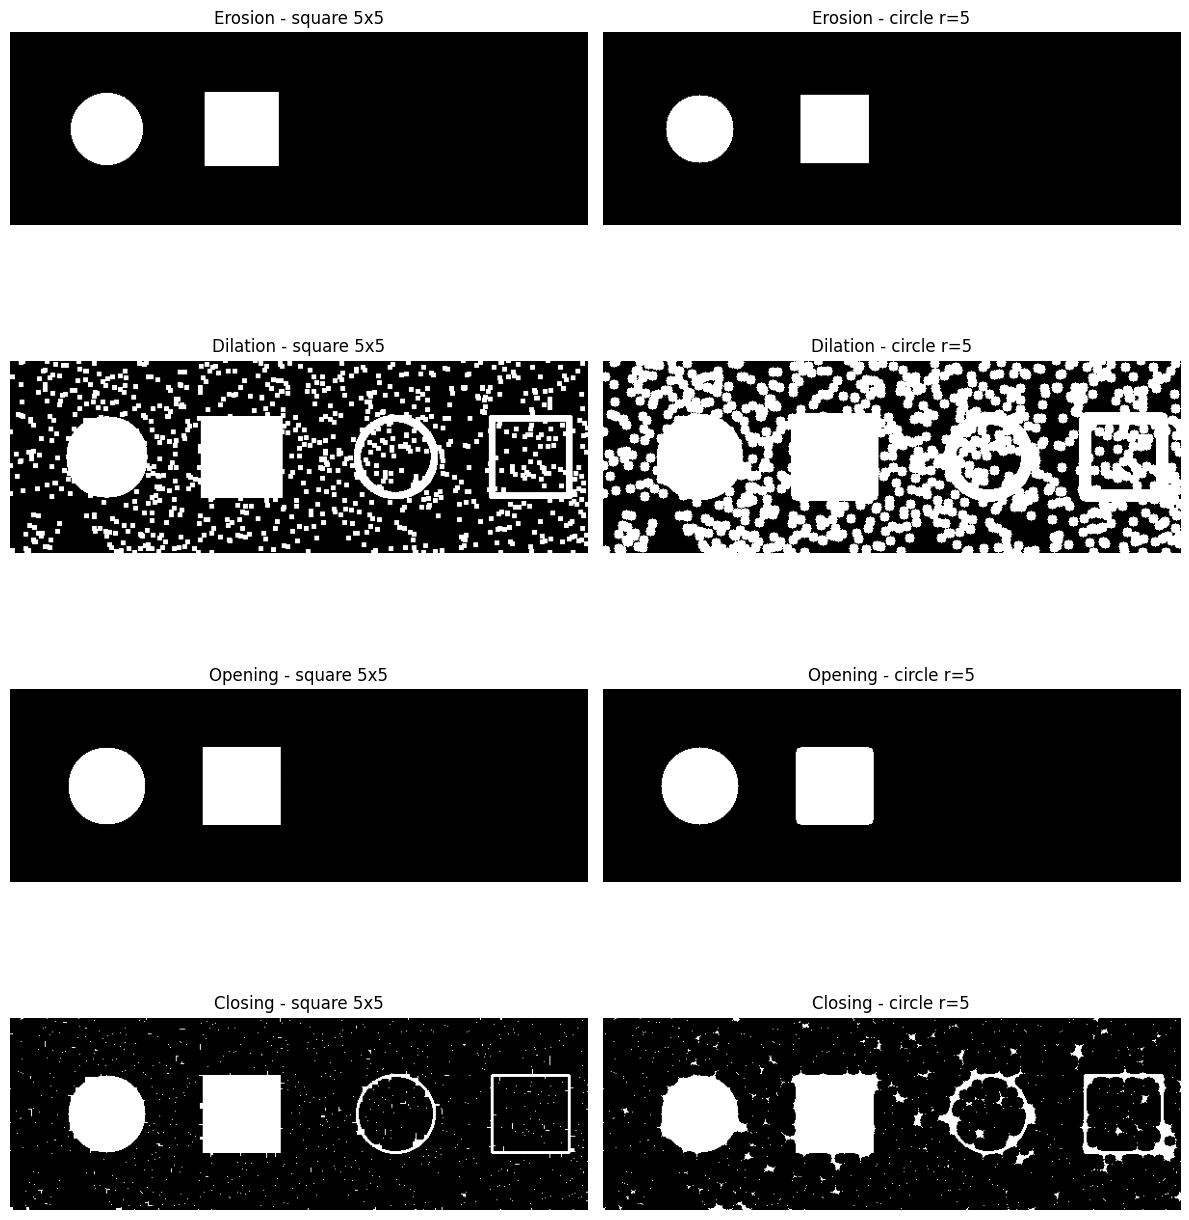

Operation   Square 5x5  Circle r=5   (original = 14165 white pixels)
erosion          10335        8903
dilation         35685       67938
opening          11583       11547
closing          14707       17834


In [6]:
# Side-by-side comparison + white-pixel counts
fig, axes = plt.subplots(4, 2, figsize=(12, 14))
for row, op in enumerate(["erosion", "dilation", "opening", "closing"]):
    axes[row, 0].imshow(square_results[op], cmap='gray'); axes[row, 0].set_title(f"{op.title()} - square 5x5")
    axes[row, 1].imshow(circle_results[op], cmap='gray'); axes[row, 1].set_title(f"{op.title()} - circle r=5")
    for a in axes[row]: a.axis('off')
plt.tight_layout(); plt.show()

print(f"{'Operation':<10}{'Square 5x5':>12}{'Circle r=5':>12}   (original = {np.count_nonzero(image)} white pixels)")
for op in ["erosion", "dilation", "opening", "closing"]:
    print(f"{op:<10}{np.count_nonzero(square_results[op]):>12}{np.count_nonzero(circle_results[op]):>12}")


**Answer (Task 3):**

Both kernels follow the same rules (erosion shrinks, dilation grows, opening removes noise, closing fills gaps), but they differ in *how much* and *in what shape*:

1. **Strength.** The circular kernel (radius 5, i.e. 11×11) is much bigger than the 5×5 square, so every effect is stronger. Dilation grows the white area to about 67,900 pixels with the circle versus about 35,700 with the square (original: about 14,200). Erosion also removes more (about 8,900 left vs 10,300).

2. **Shape of the result.** The square kernel treats all directions the same way along the axes, so it keeps the **sharp 90° corners** of the rectangles and makes the circles look slightly blocky or squarish after dilation. The circular kernel is isotropic (same in every direction), so it keeps the circles round and **rounds off the corners of the rectangles**, especially after dilation and closing.

3. **Noise removal.** The salt noise is single pixels, so opening removes it with either kernel, and the solid shapes survive almost unchanged (about 11,580 vs 11,550 white pixels left). Erosion with either kernel also deletes the noise, but it shrinks the solid shapes more with the circle.

4. **Hollow shapes.** Their outline is only 2 px thick, so erosion with either kernel erases them completely (0 pixels), and opening removes them too. Dilation thickens the outlines (more with the circle). Closing only fills small gaps, so with either kernel the hollow interiors stay empty, but the circular kernel adds more white around the outlines (about 17,800 vs 14,700 pixels in total).

**Conclusion:** The square kernel is faster and preserves rectangular corners; the circular kernel is better for round objects and gives smoother, more natural boundaries, but it changes the image more because it is larger. The kernel's shape and size should be chosen to match the objects you want to keep or remove.
